# End to end: XoFTR instead of LoFTR in the whole pipeline (Single_Image_Run, one photo at a time)

Same loop as `Single_Image_Run.ipynb`: one photo in, one answer out, truth used only to judge. The pipeline is set up **once** and the fine matcher is swapped between two passes over the **same photos**: LoFTR (`minima_loftr.ckpt`, the pipeline's matcher) and XoFTR (`minima_xoftr.ckpt`, `src/fine_matching/xoftr_matcher.py`). Everything else (coarse search, heading queries, DINO layer, decision rule, answer bar) is identical, so the difference is the fine matcher alone. The candidate-level view (inliers on right and wrong places, no decision rule) is in `XoFTR_vs_LoFTR.ipynb`.

Caveat: the decision constants (`GAMMA`, the answer bar) were set while LoFTR was the matcher. XoFTR gives more matches, so its inlier scale differs; a bar and GAMMA tuned for XoFTR could move it either way, which is not done here.

In [1]:
import os, sys, math, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)

# ------------------------------------------------------------------ settings (as Single_Image_Run, apart from the LoFTR thresholds)
DATA = os.environ.get("XL_DATA", "official")
MAP = "new"
MAP_MARGIN_M = None
N_PHOTOS = 500
N_EVAL = int(os.environ.get("XL_N", "100"))
COARSE = "edge_zncc"
USE_SEMANTIC_LAYER = True
K_PEAKS = 50
M_FINE = 10
MIN_INLIERS = 8
RANSAC_PIXELS = None
MATCHER_CONFIDENCE = 0.1        # LoFTR as chosen in LoFTR_More_Matches (threshold 0.1, confidence cut 0.1)
LOFTR_COARSE_THRESHOLD = 0.1
XOFTR_COARSE = 0.3              # XoFTR at its MINIMA defaults
XOFTR_FINE = 0.1
USE_SEMANTIC_DECISION = True
GAMMA = 1.0
USE_HEADING_QUERIES = True
HEADINGS = [-5.0, 0.0, 5.0]
SCALE_FACTORS = [1.0, 1.05]
SEED = int(os.environ.get("XL_SEED", "958476"))
plt.rcParams["figure.dpi"] = 90
print(DATA, "| photos", N_EVAL, "| seed", SEED)

nudt | photos 60 | seed 958476


# Part 1 · Set up once, load both matchers

In [2]:
from single_photo_pipeline import SinglePhotoPipeline, STAGES
from heading_query_pipeline import HeadingQueryPipeline
from src.header.scoring import points_for_error, final_score
from fine_matching.xoftr_matcher import load_xoftr_matcher

pipeline_settings = dict(semantic_layer=USE_SEMANTIC_LAYER, semantic_decision=USE_SEMANTIC_DECISION, gamma=GAMMA, k_peaks=K_PEAKS, m_fine=M_FINE,
                         matcher="loftr_minima", min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS, matcher_confidence=MATCHER_CONFIDENCE,
                         satellite=MAP if DATA == "official" else None, map_margin_m=MAP_MARGIN_M if DATA == "official" else None,
                         loftr_coarse_threshold=LOFTR_COARSE_THRESHOLD)
if USE_HEADING_QUERIES:
    pipeline = HeadingQueryPipeline(DATA, COARSE, headings=HEADINGS, scale_factors=SCALE_FACTORS, **pipeline_settings)
else:
    pipeline = SinglePhotoPipeline(DATA, COARSE, **pipeline_settings)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)
test_set, camera = pipeline.test_set, pipeline.camera

loftr_matcher = pipeline.matcher
checkpoints = ROOT / "dataset" / "NUDT" / "checkpoint" / "MINIMA"
if not (checkpoints / "minima_xoftr.ckpt").exists():
    from train import config
    checkpoints = config.find_nudt_dir() / "checkpoint" / "MINIMA"
xoftr_matcher = load_xoftr_matcher(checkpoints / "minima_xoftr.ckpt", min_confidence=XOFTR_FINE, coarse_threshold=XOFTR_COARSE, fine_threshold=XOFTR_FINE)
matchers = {"LoFTR": loftr_matcher, "XoFTR": xoftr_matcher}
warm = pipeline.run(test_set.items[0], test_set.priors[0])
print("warm-up photo: %.1f s" % warm["total"])

level 3: 0.85 m/pixel, picture 14481 x 9818, map coverage 96%
level 4: 1.20 m/pixel, picture 10240 x 6942, map coverage 96%


map store ready, took 28 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


setup done in 42.3 s
data: nudt | 500 photos available | zoom levels [3, 4]
photos: nudt | map: NUDT reference map
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=50 -> M=10) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.10 | LoFTR coarse threshold 0.1, upscale 1.0 | border 0 px, margin 0 px
DINO order weight: 100.0 | projection overrides: none (settings.GEOMETRY)
device: cuda
queries per photo: 6 (headings [-5.0, 0.0, 5.0], scale factors [1.0, 1.05]); K and M are per query


warm-up photo: 4.4 s


# Part 2 · The loop, once per matcher, on the same photos

In [3]:
def run_loop(name):
    pipeline.matcher = matchers[name]
    torch.cuda.empty_cache()
    rows, failures = [], []
    start = time.time()
    count = min(N_EVAL, len(test_set.items))
    for index in range(count):
        item = test_set.items[index]
        try:
            result = pipeline.run(item, test_set.priors[index])
        except Exception as error:
            failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
            print(name, "photo %d failed: %s" % (index, str(error)[:120]))
            continue
        truth_x, truth_y = test_set.truths[index]
        error_m = math.hypot(result["x"] - truth_x, result["y"] - truth_y)
        earned = points_for_error(error_m, item["rel_height"], camera.fx)
        row = dict(matcher=name, photo=index, height=item["rel_height"], level=result["level"], error_m=error_m, error_sigma=error_m / test_set.sigmas[index],
                   answered=result["answered"], inliers=result["inliers"], points=earned if result["answered"] else 0, t_total=result["total"],
                   t_fine=result["seconds"].get("fine", np.nan) if "fine" in result["seconds"] else np.nan)
        for label in STAGES:
            row["t_" + label] = result["seconds"][label]
        rows.append(row)
        if (index + 1) % 25 == 0:
            so_far = pd.DataFrame(rows)
            print("%s %3d/%d | score so far %.1f /60 | answered %.2f | %.1f s per photo" % (name, index + 1, count, final_score(list(so_far["points"])), so_far["answered"].mean(), so_far["t_total"].mean()))
    print("%s: %d photos in %.0f s (%d failed)" % (name, len(rows), time.time() - start, len(failures)))
    return pd.DataFrame(rows)

results = pd.concat([run_loop("LoFTR"), run_loop("XoFTR")], ignore_index=True)

LoFTR  25/60 | score so far 43.2 /60 | answered 0.84 | 4.2 s per photo


LoFTR  50/60 | score so far 42.0 /60 | answered 0.88 | 4.5 s per photo


LoFTR: 60 photos in 271 s (0 failed)


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


XoFTR  25/60 | score so far 48.0 /60 | answered 0.80 | 3.8 s per photo


XoFTR  50/60 | score so far 46.8 /60 | answered 0.84 | 4.0 s per photo


XoFTR: 60 photos in 243 s (0 failed)


# Part 3 · What came out, side by side

In [4]:
rows = []
for name, part in results.groupby("matcher", sort=False):
    rows.append({"matcher": name, "photos": len(part), "score (/60)": final_score(list(part["points"])), "answered": part["answered"].mean(),
                 "<= 1 sigma": (part["error_sigma"] <= 1).mean(), "<= 2 sigma": (part["error_sigma"] <= 2).mean(), "<= 4 sigma": (part["error_sigma"] <= 4).mean(),
                 "answered wrong (-20)": int(((part["points"] < 0)).sum()), "median error (m)": part["error_m"].median(),
                 "mean inliers (chosen)": part["inliers"].mean(), "mean s per photo": part["t_total"].mean()})
summary = pd.DataFrame(rows)
display(summary.round(3))
stage_columns = ["t_" + label for label in STAGES]
display(results.groupby("matcher", sort=False)[stage_columns].mean().round(2))

earned = []
for value, label in [(10, "within 1 sigma (+10)"), (6, "within 2 sigma (+6)"), (3, "within 4 sigma (+3)"), (0, "answered, 4 to 8 sigma (0)"), (-20, "answered, wrong place (-20)")]:
    earned.append({"what the photo earned": label, **{name: int(((part["answered"]) & (part["points"] == value)).sum()) for name, part in results.groupby("matcher", sort=False)}})
earned.append({"what the photo earned": "skipped (0)", **{name: int((~part["answered"]).sum()) for name, part in results.groupby("matcher", sort=False)}})
display(pd.DataFrame(earned))

,matcher,photos,score (/60),answered,<= 1 sigma,<= 2 sigma,<= 4 sigma,answered wrong (-20),median error (m),mean inliers (chosen),mean s per photo
0,LoFTR,60,38.0,0.833,0.767,0.767,0.767,4,4.167,49.483,4.506
1,XoFTR,60,43.0,0.767,0.767,0.783,0.800,1,4.282,65.917,4.024


,t_render,t_maps,t_coarse,t_semantic,t_fine,t_decision
matcher,,,,,,
LoFTR,0.30,1.20,0.01,0.63,2.37,0.0
XoFTR,0.29,1.17,0.01,0.61,1.94,0.0


,what the photo earned,LoFTR,XoFTR
0,within 1 sigma (+10),46,45
1,within 2 sigma (+6),0,0
2,within 4 sigma (+3),0,0
3,"answered, 4 to 8 sigma (0)",0,0
4,"answered, wrong place (-20)",4,1
5,skipped (0),10,14


## Paired difference per photo (XoFTR minus LoFTR) and where they disagree

points per photo, XoFTR - LoFTR: mean +0.83, 95% interval [-0.17, +2.17] (x 60 photos = +50.0 of /60-scale score points per 60 photos)
photos XoFTR gains: 3 | loses: 1 | same: 56


,height_loftr,error_sigma_loftr,answered_loftr,inliers_loftr,points_loftr,height_xoftr,error_sigma_xoftr,answered_xoftr,inliers_xoftr,points_xoftr,diff
photo,,,,,,,,,,,
52,313.64,0.18,True,11,10,313.64,0.62,False,6,0,-10.0
11,226.96,283.93,True,8,-20,226.96,284.32,False,4,0,20.0
43,317.82,500.45,True,8,-20,317.82,453.09,False,3,0,20.0
59,219.47,295.32,True,8,-20,219.47,213.00,False,0,0,20.0


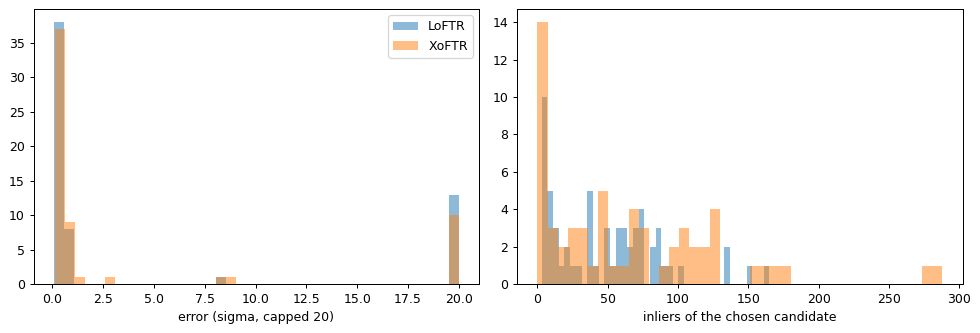

saved in /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_4/results/xoftr_vs_loftr


In [5]:
a = results[results.matcher == "LoFTR"].set_index("photo"); b = results[results.matcher == "XoFTR"].set_index("photo")
common = a.index.intersection(b.index)
diff = (b.loc[common, "points"] - a.loc[common, "points"]).to_numpy(dtype=float)
rng = np.random.default_rng(0)
means = np.array([diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(4000)])
print("points per photo, XoFTR - LoFTR: mean %+.2f, 95%% interval [%+.2f, %+.2f] (x %d photos = %+.1f of /60-scale score points per 60 photos)" % (
    diff.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5), len(diff), diff.mean() * 60))
print("photos XoFTR gains: %d | loses: %d | same: %d" % ((diff > 0).sum(), (diff < 0).sum(), (diff == 0).sum()))
columns = ["height", "error_sigma", "answered", "inliers", "points"]
both = a.loc[common, columns].join(b.loc[common, columns], lsuffix="_loftr", rsuffix="_xoftr")
both["diff"] = diff
display(both[both["diff"] != 0].sort_values("diff").round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, colour in (("LoFTR", "tab:blue"), ("XoFTR", "tab:orange")):
    part = results[results.matcher == name]
    axes[0].hist(part["error_sigma"].clip(upper=20), bins=40, alpha=0.5, color=colour, label=name)
    axes[1].hist(part["inliers"], bins=40, alpha=0.5, color=colour, label=name)
axes[0].set_xlabel("error (sigma, capped 20)"); axes[1].set_xlabel("inliers of the chosen candidate"); axes[0].legend()
plt.tight_layout(); plt.show()
out_dir = ROOT / "tests" / "Test_Iteration_4" / "results" / "xoftr_vs_loftr"
out_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(out_dir / ("pipeline_per_photo_%s_seed%d.csv" % (DATA, SEED)), index=False)
summary.to_csv(out_dir / ("pipeline_summary_%s_seed%d.csv" % (DATA, SEED)), index=False)
print("saved in", out_dir)